In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# Load dataset
df = pd.read_csv("Wholesale customers data.csv")
# First 5 rows
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
# Check data size
print(df.shape)
# column types and missing values
df.info()
# basic stats
df.describe()


(440, 8)
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [3]:
# missing values
print(df.isnull().sum())
# duplicate rows
print("Duplicates:", df.duplicated().sum())

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64
Duplicates: 0


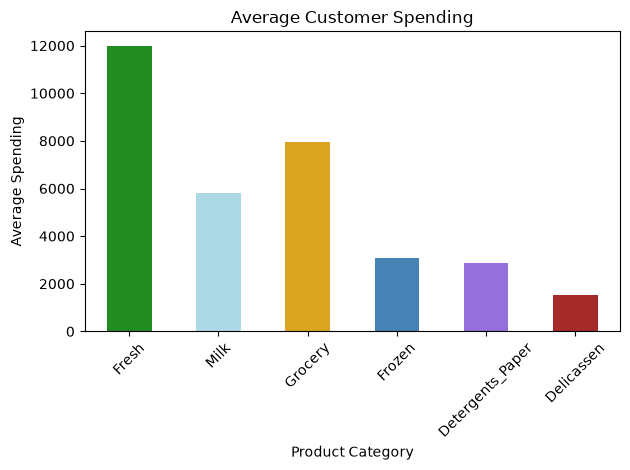

In [4]:
# select spending columns
spending = df.drop(columns=["Channel", "Region"])
colors = ["forestgreen", "lightblue", "goldenrod", "steelblue", "mediumpurple", "brown"]
# plot average spending by category
spending.mean().plot(kind="bar", color=colors)
plt.title("Average Customer Spending")
plt.xlabel("Product Category")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:

from sklearn.preprocessing import StandardScaler
# standardise the spending data
scaler = StandardScaler()
X = scaler.fit_transform(spending)
# check
print(X[:5])


[[ 0.05293319  0.52356777 -0.04111489 -0.58936716 -0.04356873 -0.06633906]
 [-0.39130197  0.54445767  0.17031835 -0.27013618  0.08640684  0.08915105]
 [-0.44702926  0.40853771 -0.0281571  -0.13753572  0.13323164  2.24329255]
 [ 0.10011141 -0.62401993 -0.3929769   0.6871443  -0.49858822  0.09341105]
 [ 0.84023948 -0.05239645 -0.07935618  0.17385884 -0.23191782  1.29934689]]


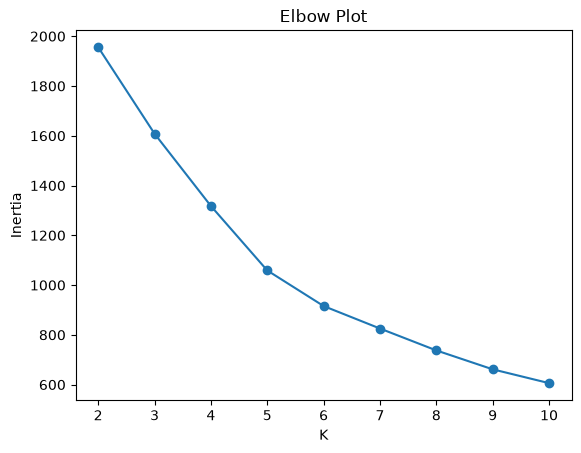

In [6]:
from sklearn.cluster import KMeans
inertias = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("K"); plt.ylabel("Inertia"); plt.title("Elbow Plot"); plt.show()

In [7]:
from sklearn.metrics import silhouette_score
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    print("K =", k, "Silhouette:", round(silhouette_score(X, labels), 2))

K = 2 Silhouette: 0.55
K = 3 Silhouette: 0.55
K = 4 Silhouette: 0.35
K = 5 Silhouette: 0.37
K = 6 Silhouette: 0.38
K = 7 Silhouette: 0.33
K = 8 Silhouette: 0.32
K = 9 Silhouette: 0.31
K = 10 Silhouette: 0.31


In [8]:
# k-means
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)
print("Silhouette:", round(silhouette_score(X, y_pred), 2))

Silhouette: 0.55


In [9]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_h = agg.fit_predict(X)
print("Silhouette:", round(silhouette_score(X, labels_h), 2))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X, labels_h), 0))

Silhouette: 0.26
Calinski-Harabasz: 111.0


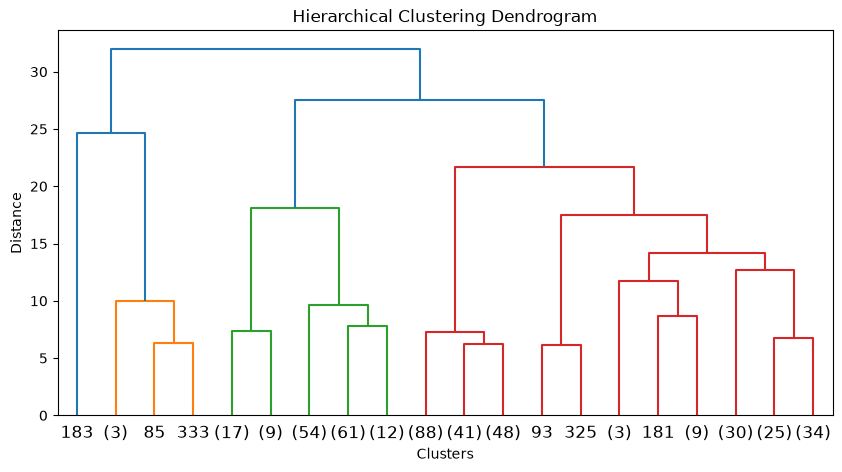

In [10]:
from scipy.cluster.hierarchy import dendrogram, linkage
# plot dendrogram
plt.figure(figsize=(10, 5))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

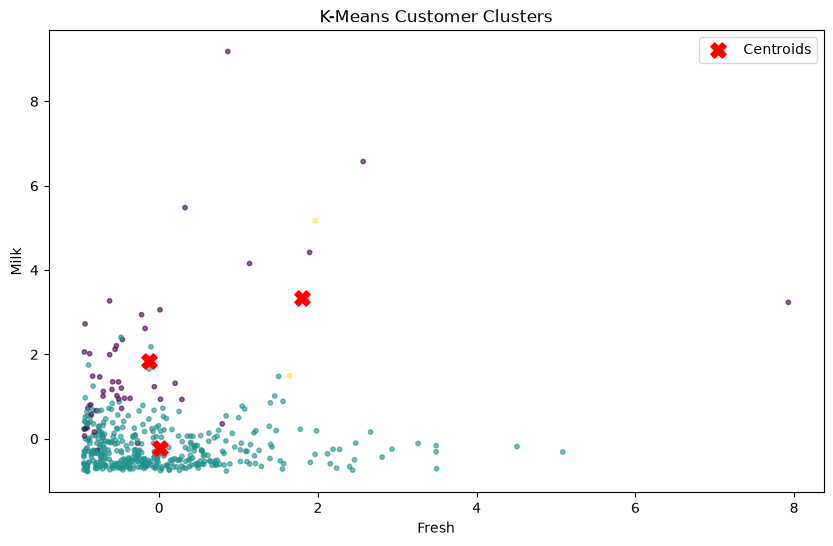

In [11]:
# plot clusters
plt.figure(figsize=(10, 6))
plt.scatter(X[:,0], X[:,1], c=y_pred, cmap="viridis", s=10, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
            c="red", s=120, marker="X", label="Centroids")
plt.legend()
plt.title("K-Means Customer Clusters")
plt.xlabel("Fresh")
plt.ylabel("Milk")
plt.show()


In [12]:
# spending across clusters
cluster_data = spending.copy()
cluster_data["Cluster"] = y_pred
cluster_data.groupby("Cluster").mean().round(0)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10441.0,19386.0,28656.0,2190.0,13328.0,2374.0
1,12063.0,4115.0,5535.0,2941.0,1696.0,1299.0
2,34782.0,30367.0,16898.0,48702.0,756.0,26776.0


In [13]:
# customers in each cluster
cluster_data["Cluster"].value_counts()


Cluster
1    393
0     45
2      2
Name: count, dtype: int64

In [14]:
# check K = 2
km = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_2 = km.fit_predict(X)
print(pd.Series(labels_2).value_counts())

0    389
1     51
Name: count, dtype: int64


In [15]:
# compare the spending for K = 2
cluster_data_2 = spending.copy()
cluster_data_2["Cluster"] = labels_2
cluster_data_2.groupby("Cluster").mean().round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,12157.0,4028.0,5403.0,3066.0,1668.0,1257.0
1,10803.0,19282.0,27390.0,3117.0,12140.0,3569.0


In [16]:
# evaluate K-means
print("Silhouette:",
round(silhouette_score(X, y_pred), 2))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X, y_pred), 0))

Silhouette: 0.55
Calinski-Harabasz: 140.0


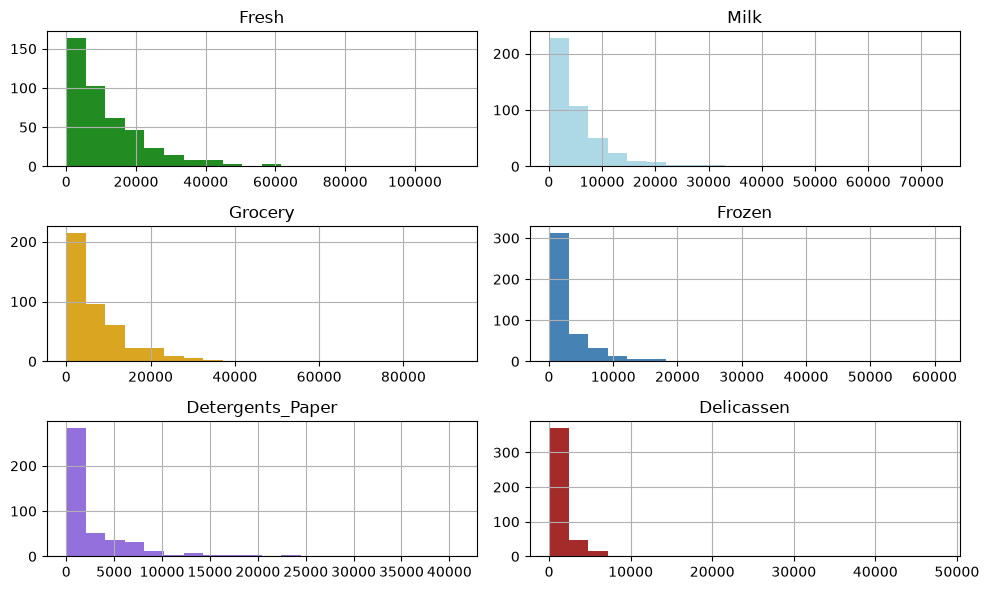

In [17]:
# spending distributions
colors = {
    "Fresh": "forestgreen",
    "Milk": "lightblue",
    "Grocery": "goldenrod",
    "Frozen": "steelblue",
    "Detergents_Paper": "mediumpurple",
    "Delicassen": "brown"}
axes = spending.hist(figsize=(10, 6), bins=20, layout=(3, 2))
for ax in axes.flatten():
    title = ax.get_title()
    for patch in ax.patches:
        patch.set_facecolor(colors[title])
plt.tight_layout()
plt.show()